# Part 1 – Load and Clean Data

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("video_game_sales.csv")
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [2]:
print(df.shape)    # (rows, columns)
print(df.dtypes)   # data type of each column
df.isnull().sum()  # missing values per column

(16598, 11)
Rank              int64
Name                str
Platform            str
Year            float64
Genre               str
Publisher           str
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object


Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [3]:
sales_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]

before = len(df)
df_clean = df.dropna(subset=sales_cols)  # drop rows only if a sales column is missing
after = len(df_clean)

print(f"Rows before: {before}, after: {after}, dropped: {before - after}")
df_clean[sales_cols].isnull().sum()      # should be all 0

Rows before: 16598, after: 16598, dropped: 0


NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

# Part 2 – Correlation Matrix Operations

#### Part 2 – Correlation Matrix
I selected only the five sales columns and used `.corr()` to calculate the Pearson correlation
coefficient matrix across all regions.

In [4]:
# Keep only the five sales columns
sales = df_clean[sales_cols]

# Pearson correlation matrix (Pearson is the default method)
corr_matrix = sales.corr()
corr_matrix.round(2)

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
NA_Sales,1.00,0.77,0.45,0.63,0.94
EU_Sales,0.77,1.00,0.44,0.73,0.90
JP_Sales,0.45,0.44,1.00,0.29,0.61
Other_Sales,0.63,0.73,0.29,1.00,0.75
Global_Sales,0.94,0.90,0.61,0.75,1.00


In [5]:
import numpy as np

# Keep only the upper triangle (k=1 excludes the diagonal self-correlations)
upper_mask = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
pairs = corr_matrix.where(upper_mask).stack()  # matrix -> Series of (row, col) pairs

# Strongest: highest coefficient
strongest_pair = pairs.idxmax()
strongest_value = pairs.max()

# Weakest: coefficient closest to 0 (smallest absolute value)
weakest_pair = pairs.abs().idxmin()
weakest_value = pairs[weakest_pair]

print(f"Strongest: {strongest_pair[0]} & {strongest_pair[1]} (r = {strongest_value:.2f})")
print(f"Weakest:   {weakest_pair[0]} & {weakest_pair[1]} (r = {weakest_value:.2f})")

Strongest: NA_Sales & Global_Sales (r = 0.94)
Weakest:   JP_Sales & Other_Sales (r = 0.29)


In [6]:
# Global_Sales is the sum of the four regions, so also check region-vs-region pairs only
region_pairs = pairs.drop("Global_Sales", level=1)  # Global only appears as the column in the upper triangle
best_region_pair = region_pairs.idxmax()

print(f"Strongest region pair: {best_region_pair[0]} & {best_region_pair[1]} (r = {region_pairs.max():.2f})")

Strongest region pair: NA_Sales & EU_Sales (r = 0.77)


#### Part2 - Summary
**Strongest pair:** `NA_Sales` & `Global_Sales` (r = 0.94).
Note that `Global_Sales` is the sum of the four regions, so this correlation is partly built in by the math.
Looking only at region-vs-region pairs, the strongest is `NA_Sales` & `EU_Sales` (r = 0.77).

**Weakest pair:** `JP_Sales` & `Other_Sales` (r = 0.29), a weak positive relationship.

# Part 3 – Visualizing the Matrix

#### Part 3 – Correlation Heatmap
The heatmap below visualizes the correlation matrix. Warmer (red) cells show stronger positive
correlations, and each cell is annotated with its coefficient.

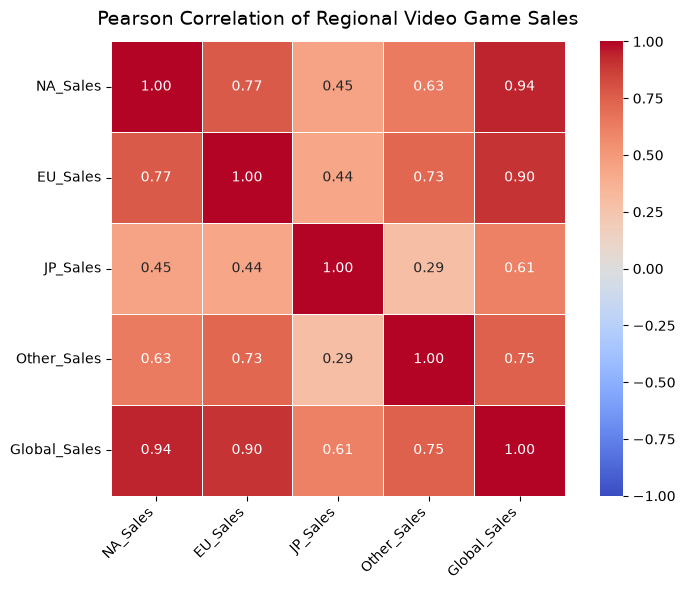

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,        # show the coefficient in each cell
    fmt=".2f",         # 2 decimal places
    cmap="coolwarm",   # blue = negative, red = positive
    vmin=-1, vmax=1,   # lock the color scale to the full r range
    linewidths=0.5,    # thin lines between cells
    square=True        # make each cell square
)

plt.title("Pearson Correlation of Regional Video Game Sales", fontsize=14, pad=12)
plt.xticks(rotation=45, ha="right")  # rotate x labels so they don't overlap
plt.yticks(rotation=0)               # keep y labels horizontal
plt.tight_layout()                   # prevent labels from being cut off
plt.show()

# Part 4 – Market Interpretation Summary

#### Part 4 – Market Interpretation Summary

- All correlations in the matrix are positive, which means **a game that sells well in one region
usually sells well in the others** too. **North America** has the strongest link to **global performance**
(r = 0.94), followed by **Europe** (r = 0.90). **Japan** has **the weakest link** (r = 0.61), so a game's
success in Japan is a less reliable signal of its worldwide success. One caution: `Global_Sales`
is the sum of the four regions, so part of these high numbers comes from the math itself.
North America is the **largest market by volume**, so it pulls the global total the most.

- Among the regions themselves, the strongest pair is North America and Europe (r = 0.77).
These markets **share similar gaming cultures**: they favor the same platforms (PlayStation, Xbox)
and the same genres (shooters, sports, action). The weakest pair is Japan and Other regions
(r = 0.29). Japan has historically preferred Nintendo, handheld consoles, and Japanese RPGs,
which are often less popular in other markets. On the other hand, the "Other" regions, such as
Australia and parts of Asia and South America, tend to follow Western trends more closely.

- For the business, this suggests that a hit in North America or Europe is likely to perform well
globally, while Japan may need its own marketing and product strategy. However, **correlation does not prove causation**,
and **a few mega-hit games can inflate** these coefficients. 
These **results** show **patterns worth investigating**, **not proof** of **why** games succeed.